# BrushCue Example: Dawn Filter

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/dawn_filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/dawn-filter

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


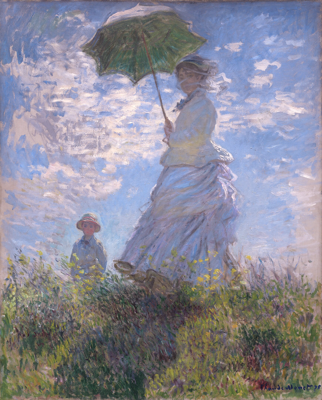

In [1]:
import io
from PIL import Image

import brushcue as bc

intensity = 0.6
input_image = bc.Composition.monet_women_with_parasol()
graph = (
    input_image.target_white_kelvin((5003.0 + (900.0 * intensity)))
    .chroma_offset(
        bc.Vector2f.from_components((0.03 * intensity), ((-0.01) * intensity))
    )
    .contrast_adjustment(((-0.35) * intensity))
    .brightness_adjust((0.05 * intensity))
    .saturation_adjust((1.0 - (0.2 * intensity)))
    .bloom(0.6, 30.0, (0.2 * intensity))
    .crop(input_image.bounds())
)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
